References:   

https://www.youtube.com/watch?v=SXeThN5S7u0 & linked git
https://github.com/The-Pocket/PocketFlow-Tutorial-Video-Generator/blob/main/docs/llm/quantization.md


https://newsletter.maartengrootendorst.com/p/a-visual-guide-to-quantization

# Quantization

## 1. Formats

| Format | Values | Range | Bytes |
|---|---|---|---|
| FP32 | decimals | huge | 4 |
| FP16 | decimals | large | 2 |
| INT8 | 2⁸ = 256 | -128 to 127 | 1 |
| INT4 | 2⁴ = 16 | -8 to 7 | 0.5 |

## 2. The Problem

- 7B weights × 4 bytes (FP32) = **28 GB**, just for the weights.
- Weights must travel from VRAM (big, slow) to the GPU cores' on-chip cache (tiny, fast) for every calculation. **That trip is the bottleneck.**
- Smaller weights = less memory and less to move = faster.

## 3. The Idea

Map each float onto one of a small set of integer **buckets** (256 for INT8), plus store one float **S (scale)** to convert back.
S = the **step size**: how much float value one integer step represents.

~~~
float:   -3.5 ............ 0.0 ............ +3.5   (infinite values)
           |                |                 |
integer: -127 ............. 0 .............. +127  (256 buckets)
               each step = S float units
~~~

## 4. Symmetric Quantization (simplest case)

Pick S so the **biggest value lands on the biggest integer** (127):

$$S = \frac{\max|x|}{127}$$

Quantize: divide by step size, then round:
$$q = \operatorname{round}\left(\frac{x}{S}\right)$$

Dequantize: multiply back:
$$\hat{x} = S \cdot q \qquad (\hat{x} = \text{"approximately } x\text{"})$$

Example: `x = [1.2, -3.5, 0.8, 2.1, -1.9, 3.5]`, `S = 3.5 / 127 = 0.02756`

| x | x / S | q (rounded) | x̂ = S·q | error |
|---|---|---|---|---|
| 1.2 | 43.54 | 44 | 1.2126 | -0.0126 |
| 0.8 | 29.03 | 29 | 0.7992 | +0.0008 |
| -3.5 | -127.0 | -127 | -3.5 | 0 |

- **Quantization error comes only from rounding.** It is the price of compression.
- Called **symmetric** because the range is balanced around 0 and 0.0 maps to integer 0. **Standard for weights**, which are roughly centered on 0.

## 5. Clamp (safety net)

Sometimes a result lands outside the integer range. **Clamp** cuts it to the nearest edge.

Example: the video computes S as float range / integer range = 7.0 / 255 = 0.02745. Then:
~~~
3.5 / 0.02745 = 127.5  →  round  →  128  (outside -128..127)  →  clamp  →  127
~~~
(With that S, 1.2 → 43.71 → 44 → 1.2078. Same idea, slightly different step size. Using 127 instead of 255 avoids hitting the edge.)

## 6. Zero-Point (Z): for lopsided data

After ReLU, activations are all ≥ 0, e.g. 0 to 10.

Symmetric on 0 to 10: S = 10/127, so values map to 0..127. **Integers -128 to -1 are never used: half the buckets wasted.**

Fix (**asymmetric**): stretch the full float range over all 256 buckets, then **shift** so the ends line up.

$$S = \frac{x_{max} - x_{min}}{q_{max} - q_{min}} = \frac{10}{255} = 0.0392$$

Z = the shift. We want $x_{min}$ to land on $q_{min}$: $q_{min} = \frac{x_{min}}{S} + Z$, so

$$Z = \operatorname{round}\left(q_{min} - \frac{x_{min}}{S}\right) = -128 - 0 = -128$$

Float 0.0 now maps to integer -128, float 10 to 127. All buckets used.
**Z = the integer that float 0.0 maps to.** Symmetric: Z = 0. Asymmetric: Z ≠ 0.

## 7. Full Formulas (Affine Quantization)

**Affine** = scale (divide/multiply by S) then shift (add/subtract Z).

$$q = \operatorname{clamp}\left(\operatorname{round}\left(\frac{x}{S} + Z\right),\ q_{min},\ q_{max}\right)$$

1. `x / S`: count steps
2. `+ Z`: shift
3. `round`: snap to nearest integer (error happens here)
4. `clamp`: keep within range

$$\hat{x} = S\,(q - Z)$$

Dequantize = reverse: undo the shift (−Z), multiply by step size (×S).

## 8. What Gets Quantized: Weights Only

Each layer computes `output = input × weights`.

| | Weights ("the brain") | Activations / inputs ("the thought") |
|---|---|---|
| Changes? | never during inference | new for every prompt and generated token |
| Lifetime | permanent in VRAM | used once, discarded |
| Size | huge (the 28 GB) | small at any moment |
| Quantize? | **yes**: this is the memory problem | **no**, stay FP16 |

Why not activations: you would need a quantize step and a dequantize step at **every layer**, which slows inference.

**On-the-fly dequantization** (how INT8 weights multiply with FP16 inputs):
1. **Store:** INT8 weights + their FP16 scale S sit in VRAM.
2. **Load:** INT8 weights travel to the core's on-chip cache (the slow trip, now smaller).
3. **Dequantize:** a dedicated circuit converts them to temporary FP16: $\hat{x} = S \cdot q$ (nanoseconds).
4. **Compute and discard:** matmul in FP16, then the temporary weights are thrown away. VRAM copy stays INT8.

Result: INT8 storage, FP16 accuracy. Two formats in one model = **mixed precision**.

## 9. The Outlier Problem

**Outlier** = one value far larger than the rest.
~~~
x = [1.2, -3.5, 0.8, 2.1, -1.9, 1000.0]
S = 1000 / 127 = 7.87

quantize 1.2:    1.2 / 7.87 = 0.15  →  round  →  0
dequantize:      7.87 × 0 = 0       the 1.2 is erased
~~~
One big value makes every step huge, so **all normal values collapse to 0**.

## 10. Fix: Granularity (more scales)

**Granularity** = how many weights share one S. Give smaller groups their **own S**, so an outlier only damages its own group.

| Level | One S per | Quality | Overhead | Used for |
|---|---|---|---|---|
| Per-tensor | whole matrix | lowest | lowest | baseline |
| Per-channel | each row (row = "channel" = one output) | good | medium | **INT8 standard** |
| Group-wise | each block of 64/128 weights in a row | highest | highest | **INT4 standard** |

~~~
Per-channel example (3 rows, row 2 has the 1000.0 outlier):
scales = [0.022, 7.87, 0.024]
Row 2 gets a big S; rows 1 and 3 keep small, precise S.
~~~

**Overhead** = the scales are extra stored data (**metadata**). Group of 128 with an FP16 scale: 16 bits / 128 = **0.125 extra bits per weight**.

**Granularity controls quality.**

## 11. INT4

Only 16 values (-8 to 7), so $S = \max|x| / 7$.
~~~
x = [0.51, 0.58, -1.2, 2.1]    S = 2.1 / 7 = 0.3
0.51 / 0.3 = 1.70 → 2
0.58 / 0.3 = 1.93 → 2          collision: two different floats, same integer
q = [2, 2, -4, 7]
~~~
So few buckets = heavy collapse → **group-wise is required**.

**Byte barrier:** hardware reads memory in whole bytes (8 bits), never 4. Fix = **packing** two 4-bit values into one byte:
1. Make them unsigned (0 to 15) by adding 8: `2 → 10`, `-4 → 4`
2. Shift the second value left by 4 (into the upper half): `4 << 4`
3. Merge with OR: `(4 << 4) | 10 = 74 = 0100 1010`

| Format | Bytes/weight | 7B model |
|---|---|---|
| FP32 | 4 | 28 GB |
| FP16 | 2 | 14 GB (usual starting point) |
| INT8 (per-channel) | 1 | 7 GB (2x smaller than FP16) |
| INT4 (group-wise) | 0.5 | 3.5 GB (4x smaller than FP16) |

## 12. When to Quantize: PTQ vs QAT

**PTQ (Post-Training Quantization):** the default.
1. Start with the trained FP16 model.
2. **Calibrate:** run ~100 sample inputs through it (no training) to observe value ranges.
3. Use those ranges to compute the best scales.
4. Convert the weights, save the model.

Why it wins: minutes on one GPU; no original training data needed (good for privacy); accuracy loss usually negligible.
Limit: the model can't adapt to rounding error.

**QAT (Quantization-Aware Training):** the backup.
- During fine-tuning, each forward pass uses **fake quantization**: round the weight to INT8, convert straight back to FP32, use this slightly damaged weight.
- The model "feels" the rounding error, and backpropagation adjusts weights to resist it.

| | PTQ | QAT |
|---|---|---|
| Complexity | low (plug and play) | high (full training pipeline) |
| Data needed | ~100 samples | full training dataset |
| Compute | minutes | days of GPU time |
| Used for | almost all modern LLMs | older vision models, tiny edge devices, very low bits |

**Rule:** start with PTQ (works for ~99% of LLM cases). Use QAT only if accuracy drops too much.

## Recap

1. **Math:** affine map, $q = \operatorname{round}(x/S + Z)$, float range squeezed into integer buckets.
2. **Hardware:** store weights as INT, compute in FP via on-the-fly dequantization.
3. **Quality:** granularity isolates outliers. Per-channel for INT8, group-wise for INT4.
4. **Strategy:** PTQ is the standard.

### Cell 1: Setup

In [1]:
# ===== 1. Setup: the two core formulas =====
import numpy as np

# Quantize: float -> int
#   q = clamp(round(x / S + Z), q_min, q_max)
def quantize(x, S, Z, q_min, q_max):
    q = np.round(x / S + Z)        # count steps, shift, snap to nearest integer
    q = np.clip(q, q_min, q_max)   # clamp: keep inside the integer range
    return q.astype(np.int8)       # store as real 1-byte integers

# Dequantize: int -> approximate float
#   x_hat = S * (q - Z)
def dequantize(q, S, Z):
    q = q.astype(np.float32)       # back to float first (int8 math would overflow)
    return S * (q - Z)             # undo the shift, multiply by step size

### Cell 2: Symmetric INT8

In [2]:
# ===== 2. Symmetric INT8 (section 4) =====
x = np.array([1.2, -3.5, 0.8, 2.1, -1.9, 3.5], dtype=np.float32)   # example FP32 weights

S = np.max(np.abs(x)) / 127        # biggest value lands on biggest integer (127)
q = quantize(x, S, Z=0, q_min=-128, q_max=127)   # Z = 0 because symmetric
x_hat = dequantize(q, S, Z=0)

print("Scale S         :", round(S, 5))
print("Original x      :", x)
print("Stored q (INT8) :", q)
print("Restored x_hat  :", x_hat.round(4))
print("Error x - x_hat :", (x - x_hat).round(4))
print("Memory (bytes)  :", x.nbytes, "FP32 ->", q.nbytes, "INT8")
# Look for: 1.2 -> 44 -> 1.2126. Tiny errors from rounding. 24 -> 6 bytes = 4x smaller.

Scale S         : 0.02756
Original x      : [ 1.2 -3.5  0.8  2.1 -1.9  3.5]
Stored q (INT8) : [  44 -127   29   76  -69  127]
Restored x_hat  : [ 1.2126 -3.5     0.7992  2.0945 -1.9016  3.5   ]
Error x - x_hat : [-0.0126  0.      0.0008  0.0055  0.0016  0.    ]
Memory (bytes)  : 24 FP32 -> 6 INT8


### Cell 3: Clamp

In [3]:
# ===== 3. Clamp in action (section 5) =====
S = 7.0 / 255                      # the video's scale: float range / integer range
x = 3.5

print("x / S     :", x / S)                           # number of steps
print("Rounded   :", np.round(x / S))                 # outside -128..127
print("Clamped q :", quantize(x, S, 0, -128, 127))    # pulled back to the edge
# Look for: 127.5 -> 128 (out of range) -> clamped to 127.

x / S     : 127.5
Rounded   : 128.0
Clamped q : 127


### Cell 4: Why Z exists

In [4]:
# ===== 4. Why Z exists: lopsided data (section 6) =====
x = np.linspace(0, 10, 1000)       # all values >= 0, like after ReLU

# Symmetric: Z = 0, so the negative integers are never used
S_sym = 10 / 127
q_sym = quantize(x, S_sym, 0, -128, 127)

# Asymmetric: stretch 0..10 over all 256 integers, then shift with Z
S_asym = 10 / 255
Z = -128                           # = round(q_min - x_min / S) = -128 - 0
q_asym = quantize(x, S_asym, Z, -128, 127)

err_sym  = np.abs(x - dequantize(q_sym, S_sym, 0)).mean()
err_asym = np.abs(x - dequantize(q_asym, S_asym, Z)).mean()

print("Symmetric  : buckets used =", len(np.unique(q_sym)),  "/ 256, avg error =", err_sym.round(4))
print("Asymmetric : buckets used =", len(np.unique(q_asym)), "/ 256, avg error =", err_asym.round(4))
# Look for: 128 vs 256 buckets used. All buckets -> smaller steps -> half the error.

Symmetric  : buckets used = 128 / 256, avg error = 0.0197
Asymmetric : buckets used = 256 / 256, avg error = 0.0098


### Cell 5: See the buckets

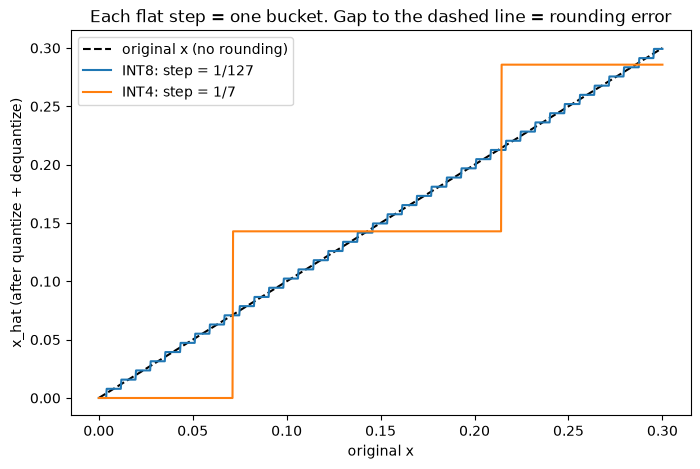

In [5]:
# ===== 5. See the buckets: INT8 vs INT4 =====
import matplotlib.pyplot as plt

# Weights range from -1 to 1 (max|x| = 1). Zoom into 0..0.3 so the steps are visible.
x = np.linspace(0, 0.3, 1000)

x_hat_int8 = dequantize(quantize(x, 1/127, 0, -128, 127), 1/127, 0)   # S = 1/127 (fine steps)
x_hat_int4 = dequantize(quantize(x, 1/7,   0, -8,   7),   1/7,   0)   # S = 1/7   (coarse steps)

plt.figure(figsize=(8, 5))
plt.plot(x, x, "k--", label="original x (no rounding)")
plt.plot(x, x_hat_int8, label="INT8: step = 1/127")
plt.plot(x, x_hat_int4, label="INT4: step = 1/7")
plt.xlabel("original x")
plt.ylabel("x_hat (after quantize + dequantize)")
plt.title("Each flat step = one bucket. Gap to the dashed line = rounding error")
plt.legend()
plt.show()
# Look for: INT8 stays almost on the dashed line (small error).
# INT4: every x from ~0.07 to ~0.21 becomes the same value 0.143 (big error, collisions).

### Cell 6: The outlier problem

In [6]:
# ===== 6. The outlier problem (section 9) =====
x = np.array([1.2, -3.5, 0.8, 2.1, -1.9, 1000.0], dtype=np.float32)   # one outlier

S = np.max(np.abs(x)) / 127        # the outlier sets S
q = quantize(x, S, 0, -128, 127)

print("Scale S         :", round(S, 2))
print("Stored q (INT8) :", q)
print("Restored x_hat  :", dequantize(q, S, 0).round(2))
# Look for: S = 7.87 (huge steps). Every normal value becomes 0 and comes back as 0: erased.

Scale S         : 7.87
Stored q (INT8) : [  0   0   0   0   0 127]
Restored x_hat  : [   0.    0.    0.    0.    0. 1000.]


### Cell 7: Per-tensor vs per-channel

In [7]:
# ===== 7. Per-tensor vs per-channel (section 10) =====
W = np.array([[ 1.2,   -0.5,  2.8,  0.9],   # row 1: max|x| = 2.8
              [-1.5, 1000.0,  0.3, -2.1],   # row 2: max|x| = 1000 (outlier)
              [ 3.1,   -2.2, -1.8,  1.1]],  # row 3: max|x| = 3.1
             dtype=np.float32)

def avg_error_per_row(W, S):
    W_hat = dequantize(quantize(W, S, 0, -128, 127), S, 0)
    return np.abs(W - W_hat).mean(axis=1).round(4)

# Per-tensor: one S for the whole matrix
S_tensor = np.max(np.abs(W)) / 127

# Per-channel: one S per row
#   axis=1        -> max of each row
#   keepdims=True -> shape (3, 1), so each row is divided by its own S
S_channel = np.max(np.abs(W), axis=1, keepdims=True) / 127

print("Per-tensor scale            :", round(S_tensor, 3))
print("Per-channel scales (rows)   :", S_channel.ravel().round(3))
print("Per-tensor  avg error (rows):", avg_error_per_row(W, S_tensor))
print("Per-channel avg error (rows):", avg_error_per_row(W, S_channel))
# Look for: rows 1 and 3 drop from ~1-2 error to ~0.005. Only row 2 stays damaged.

Per-tensor scale            : 7.874
Per-channel scales (rows)   : [0.022 7.874 0.024]
Per-tensor  avg error (rows): [1.35  0.975 2.05 ]
Per-channel avg error (rows): [0.0051 0.975  0.0028]


### Cell 8: INT4 per-channel vs group-wise

In [8]:
# ===== 8. INT4: per-channel vs group-wise (section 11) =====
row = np.random.default_rng(0).normal(0, 1, 256)   # one row of 256 normal weights
row[10] = 40.0                                     # plus one outlier

def int4_avg_error(row, group_size):
    groups = row.reshape(-1, group_size)                    # split the row into groups
    S = np.max(np.abs(groups), axis=1, keepdims=True) / 7   # one S per group (INT4 max = 7)
    groups_hat = dequantize(quantize(groups, S, 0, -8, 7), S, 0)
    return np.abs(groups - groups_hat).mean().round(4)

print("Per-channel (1 S per 256) avg error:", int4_avg_error(row, 256))
print("Group-wise  (1 S per 32)  avg error:", int4_avg_error(row, 32))
# Look for: ~0.81 vs ~0.15. The outlier only ruins its own group of 32.

Per-channel (1 S per 256) avg error: 0.8107
Group-wise  (1 S per 32)  avg error: 0.149


### Cell 9: Packing

In [9]:
# ===== 9. Packing two INT4 values into one byte (section 11) =====
a, b = 2, -4                       # two INT4 values (range -8..7)

# Pack
a_u, b_u = a + 8, b + 8            # make unsigned (0..15)
packed = (b_u << 4) | a_u          # b -> high 4 bits, a -> low 4 bits, OR merges them

# Unpack (what happens before dequantizing)
a_back = (packed & 0b1111) - 8     # keep only the low 4 bits, undo +8
b_back = (packed >> 4) - 8         # shift the high 4 bits down, undo +8

print("Original a, b    :", a, b)
print("Unsigned a, b    :", a_u, b_u)
print("Packed (decimal) :", packed)
print("Packed (binary)  :", format(packed, "08b"))
print("Unpacked a, b    :", a_back, b_back)
# Look for: two numbers stored in one byte (74 = 0100 1010) and recovered exactly.

Original a, b    : 2 -4
Unsigned a, b    : 10 4
Packed (decimal) : 74
Packed (binary)  : 01001010
Unpacked a, b    : 2 -4


### Cell 10: BF16 vs FP16

In [10]:
# ===== 10. BF16 vs FP16: range vs precision (section 0, needs PyTorch) =====
import torch

big  = torch.tensor(70000.0)       # above FP16 max (65,504): tests range
fine = torch.tensor(1.001)         # needs fine detail: tests precision

print("Range     | 70000 in FP16 :", big.half().item())
print("Range     | 70000 in BF16 :", big.bfloat16().item())
print("Precision | 1.001 in FP16 :", fine.half().item())
print("Precision | 1.001 in BF16 :", fine.bfloat16().item())
# Look for: FP16 overflows to inf (5 exponent bits) but keeps 1.001 close (10 mantissa bits).
# BF16 holds 70000 (8 exponent bits) but rounds 1.001 to 1.0 (7 mantissa bits).

Range     | 70000 in FP16 : inf
Range     | 70000 in BF16 : 70144.0
Precision | 1.001 in FP16 : 1.0009765625
Precision | 1.001 in BF16 : 1.0


## Picture Reference

### Section 0: Range vs Precision (FP32, BF16, FP16, INT8)
<img src="https://substack-post-media.s3.amazonaws.com/public/images/7dbb8398-9f3f-4d9a-b63f-591cb37bdbdd_1144x856.png" width="343">

Exponent bits set the range, mantissa bits set the precision. INT8's range is tiny.

---

### Section 3: The Idea (Floats Snap to Buckets)
<img src="https://substack-post-media.s3.amazonaws.com/public/images/82ac8f88-0cf5-4244-ba9f-cbffdb283947_1008x496.png" width="302">

Continuous weights (purple) get snapped to a small set of discrete buckets (red).

---

### Section 4: Symmetric Mapping (absmax)
<img src="https://substack-post-media.s3.amazonaws.com/public/images/782beaa8-340f-45b8-ba7f-20491f66867a_1172x848.png" width="352">

Largest absolute value lands on 127. Float 0 stays integer 0.

---

### Section 4: Quantize and Dequantize Round Trip
<img src="https://substack-post-media.s3.amazonaws.com/public/images/5ea2d627-efc7-4a8a-9cf0-7a7020f1253d_1236x348.png" width="371">

Small errors after the round trip. 3.08 and 3.02 both become 36: collision.

---

### Section 4: Quantization Error
<img src="https://substack-post-media.s3.amazonaws.com/public/images/e173b13b-ed99-4de0-a5e0-4b9114899b3f_1236x372.png" width="371">

Error = original minus dequantized. Every cell loses a little, caused by rounding.

---

### Section 5: Clamp (Values Beyond the Range)
<img src="https://substack-post-media.s3.amazonaws.com/public/images/52511453-ca48-42ca-9818-d1afa6dd7369_1120x408.png" width="336">

Range deliberately set to -5..5. Anything beyond it is clamped to the edge (127). Normal values keep their precision; only the outlier pays.

---

### Section 6: Symmetric vs Asymmetric (Zero-Point)
<img src="https://substack-post-media.s3.amazonaws.com/public/images/01404566-e2ae-4e3f-9101-cafc68d92b40_1172x716.png" width="352">

Asymmetric: float 0 no longer lands on integer 0. That shift is Z.

---

### Section 8: Weights Are Static, Activations Are Dynamic
<img src="https://substack-post-media.s3.amazonaws.com/public/images/7d79e60e-92ea-4c91-bbdb-297c819cd821_1456x440.png" width="437">

<img src="https://substack-post-media.s3.amazonaws.com/public/images/6baaee7f-40dd-4f6a-9a8d-bd79a7b2abc7_1456x520.png" width="437">

Weights and bias are fixed after training (quantize once). Inputs and outputs change every forward pass.

---

### Section 9: The Outlier Problem
<img src="https://substack-post-media.s3.amazonaws.com/public/images/72052ddb-1c54-45b3-9800-2c4335cc9581_1120x564.png" width="336">

One outlier stretches the range, so every normal value collapses to 0.

---

### Section 12: QAT Fake Quantization
<img src="https://substack-post-media.s3.amazonaws.com/public/images/c3a17734-65f8-45d7-8e4e-f7bc1c592577_1824x360.png" width="547">

During training, each layer's output is quantized to INT4 and immediately dequantized back, so the model trains on the rounding error.

---

### Section 12: Why QAT Works (Wide vs Narrow Minima)
<img src="https://substack-post-media.s3.amazonaws.com/public/images/b26d3f00-f599-4c75-beb4-21d87625b1d8_1200x640.png" width="360">

PTQ (right): best FP32 weight sits in a narrow valley, so rounding to INT4 jumps loss up. QAT (left): steers to a wide valley, where rounding barely changes loss.

---

*Images: [A Visual Guide to Quantization, Maarten Grootendorst](https://newsletter.maartengrootendorst.com/p/a-visual-guide-to-quantization)*